# Báo Cáo Thực Nghiệm: Mạng Tích Chập 1D (1D CNN) Văn Bản Bằng PyTorch
## Bài Toán: Phân Loại Cảm Xúc Bình Luận Khách Hàng (NLP Sentiment Classification)
**Học phần:** Phát triển Hệ thống Thông minh (Intelligent System Development)  
**Nhiệm vụ:** Assignment 04 - Ánh xạ kiến trúc 1D CNN văn bản sang PyTorch (`nn.Embedding`, `nn.Conv1d`, Autograd)  
**Dữ liệu:** `Womens Clothing E-Commerce Reviews.csv` (23,486 đánh giá)


In [1]:
import os
import re
import time
import json
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

RANDOM_SEED = 42
torch.manual_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

device = torch.device('mps' if torch.backends.mps.is_available() else ('cuda' if torch.cuda.is_available() else 'cpu'))
print(f"Thiết bị tính toán: {device}")


Thiết bị tính toán: mps


### 1. Đọc & Tiền Xử Lý Dữ Liệu Đồng Bộ


In [2]:
DATA_PATH = "../../../Assigment 02/customer_behavior/data/Womens Clothing E-Commerce Reviews.csv"
if not os.path.exists(DATA_PATH):
    DATA_PATH = "src/Assigment 02/customer_behavior/data/Womens Clothing E-Commerce Reviews.csv"

df_raw = pd.read_csv(DATA_PATH)
df_clean = df_raw.dropna(subset=['Review Text', 'Recommended IND']).copy()
df_clean['Recommended IND'] = df_clean['Recommended IND'].astype(int)

def clean_text(text):
    return re.findall(r'[a-zA-Z]+', str(text).lower())

tokenized_texts = [clean_text(t) for t in df_clean['Review Text']]
word_counts = Counter(word for doc in tokenized_texts for word in doc)
VOCAB_SIZE = 3000
MAX_LEN = 50

most_common = word_counts.most_common(VOCAB_SIZE - 2)
word2idx = {word: idx + 2 for idx, (word, _) in enumerate(most_common)}
word2idx['<PAD>'] = 0
word2idx['<UNK>'] = 1

def text_to_sequence(tokens, max_len=MAX_LEN):
    seq = [word2idx.get(w, 1) for w in tokens[:max_len]]
    if len(seq) < max_len:
        seq = seq + [0] * (max_len - len(seq))
    return seq

X_sequences = np.array([text_to_sequence(t) for t in tokenized_texts], dtype=np.int64)
y_labels = df_clean['Recommended IND'].values.astype(np.float32)

X_train, X_test, y_train, y_test = train_test_split(
    X_sequences, y_labels, test_size=0.20, random_state=RANDOM_SEED, stratify=y_labels
)

X_train_t = torch.tensor(X_train, dtype=torch.long)
y_train_t = torch.tensor(y_train[:, np.newaxis], dtype=torch.float32)
X_test_t = torch.tensor(X_test, dtype=torch.long)
y_test_t = torch.tensor(y_test[:, np.newaxis], dtype=torch.float32)

train_loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=128, shuffle=True)
test_loader = DataLoader(TensorDataset(X_test_t, y_test_t), batch_size=256, shuffle=False)

print(f"Số lượng mẫu huấn luyện: {len(train_loader.dataset):,} mẫu")


Số lượng mẫu huấn luyện: 18,112 mẫu


### 2. Định Nghĩa Kiến Trúc 1D CNN Văn Bản Bằng PyTorch
- `nn.Embedding(VOCAB_SIZE, EMBED_DIM)`
- `nn.Conv1d(in_channels=EMBED_DIM, out_channels=32, kernel_size=3)`
- `nn.ReLU()`
- `nn.MaxPool1d(2)`
- `nn.Flatten()`
- `nn.Linear(32 * 24, 16)`
- `nn.ReLU()`
- `nn.Linear(16, 1)`
- `nn.Sigmoid()`


In [3]:
class TextCNN1D(nn.Module):
    def __init__(self, vocab_size=3000, embed_dim=32):
        super(TextCNN1D, self).__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.conv = nn.Sequential(
            nn.Conv1d(in_channels=embed_dim, out_channels=32, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2),
            nn.Flatten(),
            nn.Linear(32 * 24, 16),
            nn.ReLU(),
            nn.Linear(16, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        # x: (batch_size, seq_len)
        emb = self.embedding(x) # (batch_size, seq_len, embed_dim)
        emb = emb.transpose(1, 2) # (batch_size, embed_dim, seq_len) for Conv1D
        return self.conv(emb)

model = TextCNN1D().to(device)
print(model)


TextCNN1D(
  (embedding): Embedding(3000, 32, padding_idx=0)
  (conv): Sequential(
    (0): Conv1d(32, 32, kernel_size=(3,), stride=(1,))
    (1): ReLU()
    (2): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Flatten(start_dim=1, end_dim=-1)
    (4): Linear(in_features=768, out_features=16, bias=True)
    (5): ReLU()
    (6): Linear(in_features=16, out_features=1, bias=True)
    (7): Sigmoid()
  )
)


### 3. Huấn Luyện Mô Hình Bằng PyTorch


In [4]:
criterion = nn.BCELoss()
optimizer = optim.Adam(model.parameters(), lr=0.002)
epochs = 8

history = {"loss": [], "val_loss": [], "val_acc": [], "val_f1": []}

start_time = time.time()
print("Bắt đầu huấn luyện mô hình 1D CNN Văn bản PyTorch...")

for epoch in range(1, epochs + 1):
    model.train()
    running_loss = 0.0
    for batch_x, batch_y in train_loader:
        batch_x, batch_y = batch_x.to(device), batch_y.to(device)
        
        optimizer.zero_grad()
        outputs = model(batch_x)
        loss = criterion(outputs, batch_y)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * len(batch_y)
        
    epoch_loss = running_loss / len(train_loader.dataset)
    
    model.eval()
    val_loss = 0.0
    all_preds, all_targets = [], []
    with torch.no_grad():
        for val_x, val_y in test_loader:
            val_x, val_y = val_x.to(device), val_y.to(device)
            preds = model(val_x)
            v_loss = criterion(preds, val_y)
            val_loss += v_loss.item() * len(val_y)
            all_preds.extend(preds.cpu().numpy().ravel())
            all_targets.extend(val_y.cpu().numpy().ravel())
            
    val_loss = val_loss / len(test_loader.dataset)
    val_binary = (np.array(all_preds) >= 0.5).astype(int)
    val_acc = accuracy_score(all_targets, val_binary)
    val_f1 = f1_score(all_targets, val_binary, zero_division=0)
    
    history["loss"].append(epoch_loss)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)
    history["val_f1"].append(val_f1)
    
    print(f"Epoch {epoch:02d}/{epochs:02d} - Train Loss: {epoch_loss:.4f} | Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f} | Val F1: {val_f1:.4f}")

train_time = time.time() - start_time
print(f"\nHuấn luyện PyTorch hoàn tất trong: {train_time:.2f} giây!")


Bắt đầu huấn luyện mô hình 1D CNN Văn bản PyTorch...


Epoch 01/08 - Train Loss: 0.4346 | Val Loss: 0.3686 | Val Acc: 0.8189 | Val F1: 0.9005


Epoch 02/08 - Train Loss: 0.3244 | Val Loss: 0.3322 | Val Acc: 0.8512 | Val F1: 0.9126


Epoch 03/08 - Train Loss: 0.2778 | Val Loss: 0.3271 | Val Acc: 0.8605 | Val F1: 0.9174


Epoch 04/08 - Train Loss: 0.2412 | Val Loss: 0.3274 | Val Acc: 0.8547 | Val F1: 0.9113


Epoch 05/08 - Train Loss: 0.2095 | Val Loss: 0.3352 | Val Acc: 0.8521 | Val F1: 0.9091


Epoch 06/08 - Train Loss: 0.1818 | Val Loss: 0.4062 | Val Acc: 0.8602 | Val F1: 0.9163


Epoch 07/08 - Train Loss: 0.1553 | Val Loss: 0.4872 | Val Acc: 0.8565 | Val F1: 0.9131


Epoch 08/08 - Train Loss: 0.1310 | Val Loss: 0.5690 | Val Acc: 0.8563 | Val F1: 0.9126

Huấn luyện PyTorch hoàn tất trong: 8.62 giây!


### 4. Đánh Giá Toàn Diện & Trực Quan Hóa Kết Quả


=== KẾT QUẢ ĐÁNH GIÁ 1D CNN VĂN BẢN (PYTORCH) ===
• Accuracy : 0.8563
• Precision: 0.9086
• Recall   : 0.9167
• F1-Score : 0.9126
• ROC-AUC  : 0.8762
• Thời gian: 8.62 giây


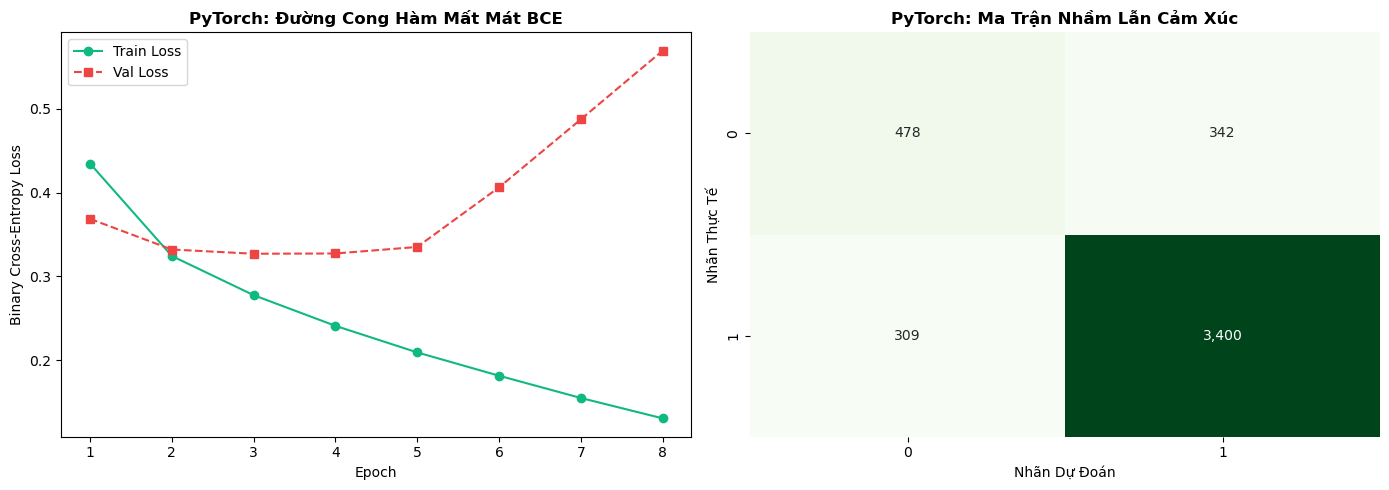

In [5]:
model.eval()
with torch.no_grad():
    y_prob = model(X_test_t.to(device)).cpu().numpy().ravel()
y_pred = (y_prob >= 0.5).astype(int)

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, zero_division=0)
rec = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
auc = roc_auc_score(y_test, y_prob)

print(f"=== KẾT QUẢ ĐÁNH GIÁ 1D CNN VĂN BẢN (PYTORCH) ===")
print(f"• Accuracy : {acc:.4f}")
print(f"• Precision: {prec:.4f}")
print(f"• Recall   : {rec:.4f}")
print(f"• F1-Score : {f1:.4f}")
print(f"• ROC-AUC  : {auc:.4f}")
print(f"• Thời gian: {train_time:.2f} giây")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(range(1, epochs + 1), history["loss"], 'o-', color='#10b981', label='Train Loss')
axes[0].plot(range(1, epochs + 1), history["val_loss"], 's--', color='#ef4444', label='Val Loss')
axes[0].set_title('PyTorch: Đường Cong Hàm Mất Mát BCE', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Binary Cross-Entropy Loss')
axes[0].legend()

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt=',d', cmap='Greens', ax=axes[1], cbar=False)
axes[1].set_title('PyTorch: Ma Trận Nhầm Lẫn Cảm Xúc', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Nhãn Dự Đoán')
axes[1].set_ylabel('Nhãn Thực Tế')

plt.tight_layout()
os.makedirs("../reports/figures", exist_ok=True)
plt.savefig("../reports/figures/02_comments_pytorch_results.png", dpi=300)
plt.show()


### 5. Lưu Trữ Kết Quả Thực Nghiệm


In [6]:
results_df = pd.DataFrame([{
    "Framework": "PyTorch",
    "Dataset": "Customer Comments (23.5k)",
    "Accuracy": acc,
    "Precision": prec,
    "Recall": rec,
    "F1": f1,
    "ROC_AUC": auc,
    "Train_Time_Sec": train_time,
    "Epochs": epochs,
    "Batch_Size": 128
}])

results_df.to_csv("../reports/model_results_pytorch.csv", index=False)
print("Đã lưu kết quả thành công vào ../reports/model_results_pytorch.csv")
results_df


Đã lưu kết quả thành công vào ../reports/model_results_pytorch.csv


,Framework,Dataset,Accuracy,Precision,Recall,F1,ROC_AUC,Train_Time_Sec,Epochs,Batch_Size
0,PyTorch,Customer Comments (23.5k),0.85626,0.908605,0.916689,0.912629,0.876232,8.62207,8,128
